# Notebook mẫu: huấn luyện và đánh giá một mô hình (E1, E2)

**Cách dùng**
1. Copy file này thành `04_models_<tên bạn>.ipynb` (không sửa file mẫu).
2. Đổi `AUTHOR` và `MODEL_NAME` ở cell đầu.
3. Thay mô hình ở cell *Mô hình của bạn* (mẫu đang dùng Logistic Regression). Phần còn lại giữ nguyên.
4. Chạy *Restart & Run All*. Kết quả tự ghi vào `reports/results/<AUTHOR>.csv` và xác suất vào `models/`.

**Quy tắc**
- Chỉ dùng `train` và `val`. Không mở `test` (hàm đọc sẽ báo lỗi).
- Mọi bước học số liệu nằm trong `Pipeline`, fit trên train.
- Chọn ngưỡng và tinh chỉnh tham số trên `val`, không bao giờ trên `test`.
- Nếu AUC hoặc F1 cao bất thường (ví dụ trên 0,95), nghi ngờ rò rỉ dữ liệu trước khi vui mừng.

In [16]:
%pip install scikit-learn
import sys; sys.path.insert(0, "..")   # để import được thư mục src/

import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from src.data import load_xy, SEED
from src.features import build_preprocessor, check_columns
from src.evaluate import evaluate, evaluate_by_group, log_result, save_proba

AUTHOR = "nguoi2"          # đổi thành tên bạn, viết thường không dấu, ví dụ "an"
MODEL_NAME = "logreg"       # tên ngắn của mô hình, dùng đặt tên file xác suất

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Đọc dữ liệu

In [17]:
X_train, y_train = load_xy("train")
X_val, y_val = load_xy("val")
check_columns(X_train)   # báo lỗi nếu có cột lạ hoặc thiếu cột
print(f"train {X_train.shape}, tỷ lệ hủy {y_train.mean():.1%}")
print(f"val   {X_val.shape}, tỷ lệ hủy {y_val.mean():.1%}")

train (40688, 24), tỷ lệ hủy 24.0%
val   (14400, 24), tỷ lệ hủy 28.4%


## Baseline

Luôn bắt đầu từ mốc này. Mô hình đoán "không hủy" cho mọi đơn sẽ cho accuracy cao nhưng recall bằng 0: đó là lý do không dùng accuracy một mình.

In [18]:
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
m_dummy = evaluate(y_val, dummy.predict_proba(X_val)[:, 1])
log_result(AUTHOR, "E1", "dummy", "val", m_dummy)
pd.Series(m_dummy)

n                14400.000000
positive_rate        0.284028
threshold            0.500000
accuracy             0.715972
precision            0.000000
recall               0.000000
f1                   0.000000
roc_auc              0.500000
pr_auc               0.284028
tn               10310.000000
fp                   0.000000
fn                4090.000000
tp                   0.000000
dtype: float64

## Mô hình của bạn (E1)

**Chỗ cần sửa:** thay `LogisticRegression(...)` bằng mô hình của bạn và chọn `kind`:
- `"linear"` cho Logistic Regression và MLP (cần chuẩn hóa, one-hot)
- `"tree"` cho Decision Tree, Random Forest, XGBoost, LightGBM

In [19]:
model = Pipeline([
    ("prep", build_preprocessor("linear")),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
model.fit(X_train, y_train)

proba_val = model.predict_proba(X_val)[:, 1]
m = evaluate(y_val, proba_val, threshold=0.5)
log_result(AUTHOR, "E1", MODEL_NAME, "val", m)
save_proba(MODEL_NAME, proba_val, split="val")
pd.Series(m)

n                14400.000000
positive_rate        0.284028
threshold            0.500000
accuracy             0.735278
precision            0.643892
recall               0.152078
f1                   0.246044
roc_auc              0.781986
pr_auc               0.571386
tn                9966.000000
fp                 344.000000
fn                3468.000000
tp                 622.000000
dtype: float64

Chỉ số tách theo khách sạn (yêu cầu báo cáo theo nhóm, không chỉ con số tổng):

In [20]:
evaluate_by_group(y_val, proba_val, X_val["hotel"]).round(3)

,n,positive_rate,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
City Hotel,9262.0,0.319,0.5,0.698,0.604,0.158,0.250,0.777,0.587,5999.0,306.0,2491.0,466.0
Resort Hotel,5138.0,0.221,0.5,0.802,0.804,0.138,0.235,0.774,0.511,3967.0,38.0,977.0,156.0


## E2: xử lý mất cân bằng lớp

Thử `class_weight="balanced"` trước (một tham số, không thêm dữ liệu, không rủi ro rò rỉ). SMOTE nếu dùng thì chỉ áp dụng trong Pipeline của `imblearn`, trên tập huấn luyện.

In [21]:
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from src.features import build_preprocessor
from src.evaluate import evaluate, log_result, save_proba

# 1. Khởi tạo mô hình RF với class_weight
rf_bal = RandomForestClassifier(
    n_estimators=200, 
    max_depth=10, 
    class_weight="balanced", # Xử lý mất cân bằng
    random_state=42, 
    n_jobs=-1
)

# 2. Tạo Pipeline (Dùng ImbPipeline để an toàn cho các bước sau)
model_bal = ImbPipeline(steps=[
    ("prep", build_preprocessor("tree")), # Dùng bộ tree cho RF
    ("clf", rf_bal)
])

# 3. Huấn luyện
model_bal.fit(X_train, y_train)

# 4. Dự đoán & Đánh giá
proba_bal = model_bal.predict_proba(X_val)[:, 1]
m_bal = evaluate(y_val, proba_bal, threshold=0.5)

# 5. Ghi kết quả
log_result(AUTHOR, "E2", "rf_balanced", "val", m_bal, note="class_weight=balanced")
save_proba("rf_balanced", proba_bal, split="val")

# In kết quả ra màn hình để dễ nhìn
print(f"RF + class_weight -> ROC-AUC: {m_bal['roc_auc']:.4f}, PR-AUC: {m_bal['pr_auc']:.4f}")

RF + class_weight -> ROC-AUC: 0.7696, PR-AUC: 0.5695


In [22]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from src.features import build_preprocessor
from src.evaluate import evaluate, log_result, save_proba

# 1. Khởi tạo SMOTE và RF (không dùng class_weight vì đã có SMOTE)
rf_smote = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)

# 2. Pipeline của imblearn
model_smote = ImbPipeline(steps=[
    ("prep", build_preprocessor("tree")),
    ("smote", SMOTE(random_state=42)),
    ("clf", rf_smote)
])

# 3. Huấn luyện
model_smote.fit(X_train, y_train)

# 4. Đánh giá
proba_smote = model_smote.predict_proba(X_val)[:, 1]
m_smote = evaluate(y_val, proba_smote, threshold=0.5)

# 5. Ghi kết quả
log_result(AUTHOR, "E2", "rf_smote", "val", m_smote, note="SMOTE")
save_proba("rf_smote", proba_smote, split="val")

print(f"RF + SMOTE -> ROC-AUC: {m_smote['roc_auc']:.4f}, PR-AUC: {m_smote['pr_auc']:.4f}")

RF + SMOTE -> ROC-AUC: 0.7953, PR-AUC: 0.5879


## So sánh

In [24]:
cols = ["precision", "recall", "f1", "roc_auc", "pr_auc", "accuracy"]
pd.DataFrame({"baseline": m_dummy, MODEL_NAME: m, MODEL_NAME + " + balanced": m_bal}).T[cols].round(3)

,precision,recall,f1,roc_auc,pr_auc,accuracy
baseline,0.000,0.000,0.000,0.500,0.284,0.716
logreg,0.644,0.152,0.246,0.782,0.571,0.735
logreg + balanced,0.590,0.420,0.490,0.770,0.570,0.752


In [25]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from src.data import load_xy
from src.features import build_preprocessor
from src.evaluate import evaluate, log_result

# 1. Lấy dữ liệu Train và Val (Tuyệt đối không dùng Test)
X_train, y_train = load_xy("train")
X_val, y_val = load_xy("val")

# Gộp lại thành một tập chung để chia lại
X_all = pd.concat([X_train, X_val])
y_all = pd.concat([y_train, y_val])

# 2. Cách 1: Chia NGẪU NHIÊN (Trộn lẫn quá khứ và tương lai)
X_tr_rand, X_va_rand, y_tr_rand, y_va_rand = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
)

rf_rand = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
pipe_rand = Pipeline([
    ("prep", build_preprocessor("tree")),
    ("clf", rf_rand)
])
pipe_rand.fit(X_tr_rand, y_tr_rand)
proba_rand = pipe_rand.predict_proba(X_va_rand)[:, 1]
m_rand = evaluate(y_va_rand, proba_rand, threshold=0.5)

log_result(AUTHOR, "E5", "rf_random_split", "val", m_rand, note="Chia ngẫu nhiên")
print(f"1. Chia NGẪU NHIÊN -> ROC-AUC: {m_rand['roc_auc']:.4f}, PR-AUC: {m_rand['pr_auc']:.4f}")

# 3. Cách 2: Chia THEO THỜI GIAN (Giữ nguyên train.csv và val.csv ban đầu)
rf_time = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
pipe_time = Pipeline([
    ("prep", build_preprocessor("tree")),
    ("clf", rf_time)
])
pipe_time.fit(X_train, y_train)
proba_time = pipe_time.predict_proba(X_val)[:, 1]
m_time = evaluate(y_val, proba_time, threshold=0.5)

log_result(AUTHOR, "E5", "rf_time_split", "val", m_time, note="Chia theo thời gian")
print(f"2. Chia THEO THỜI GIAN -> ROC-AUC: {m_time['roc_auc']:.4f}, PR-AUC: {m_time['pr_auc']:.4f}")

1. Chia NGẪU NHIÊN -> ROC-AUC: 0.8594, PR-AUC: 0.6846
2. Chia THEO THỜI GIAN -> ROC-AUC: 0.7884, PR-AUC: 0.5920


In [26]:
# Lấy lại dữ liệu gốc (chưa gộp)
X_train, y_train = load_xy("train")
X_val, y_val = load_xy("val")

# Tách dữ liệu theo loại khách sạn
X_train_city = X_train[X_train['hotel'] == 'City Hotel']
y_train_city = y_train[X_train['hotel'] == 'City Hotel']

X_val_resort = X_val[X_val['hotel'] == 'Resort Hotel']
y_val_resort = y_val[X_val['hotel'] == 'Resort Hotel']

X_train_resort = X_train[X_train['hotel'] == 'Resort Hotel']
y_train_resort = y_train[X_train['hotel'] == 'Resort Hotel']

X_val_city = X_val[X_val['hotel'] == 'City Hotel']
y_val_city = y_val[X_val['hotel'] == 'City Hotel']

# Hàm huấn luyện và đánh giá nhanh
def train_and_eval(X_tr, y_tr, X_va, y_va, name):
    rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
    pipe = Pipeline([
        # Bỏ cột 'hotel' đi để mô hình không học thuộc lòng tên khách sạn
        ("prep", build_preprocessor("tree", drop=["hotel"])),
        ("clf", rf)
    ])
    pipe.fit(X_tr, y_tr)
    proba = pipe.predict_proba(X_va)[:, 1]
    m = evaluate(y_va, proba, threshold=0.5)
    log_result(AUTHOR, "E6", name, "val", m, note=name)
    print(f"{name} -> ROC-AUC: {m['roc_auc']:.4f}, PR-AUC: {m['pr_auc']:.4f}")

# 1. Train City -> Test Resort
train_and_eval(X_train_city, y_train_city, X_val_resort, y_val_resort, "City_to_Resort")

# 2. Train Resort -> Test City
train_and_eval(X_train_resort, y_train_resort, X_val_city, y_val_city, "Resort_to_City")

# 3. Train All (Baseline) -> Test All
train_and_eval(X_train, y_train, X_val, y_val, "All_to_All")

City_to_Resort -> ROC-AUC: 0.6393, PR-AUC: 0.4133
Resort_to_City -> ROC-AUC: 0.6110, PR-AUC: 0.4644
All_to_All -> ROC-AUC: 0.7779, PR-AUC: 0.5847


C:\Users\Manh\AppData\Local\Temp\ipykernel_21804\3830563866.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=error_by_deposit, x='deposit_type', y='is_error', palette='viridis')


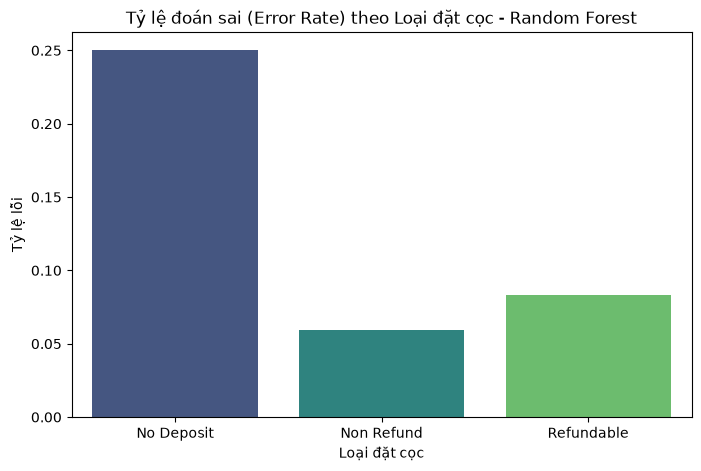

<Figure size 640x480 with 0 Axes>

In [4]:
import sys
sys.path.insert(0, "..") # Thêm dòng này để nhận diện thư mục src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data import load_xy

# 1. Load dữ liệu và xác suất (Dùng file rf_balanced)
X_val, y_val = load_xy("val")
proba_rf = np.load("../models/proba_val_rf_balanced.npy") 

# 2. Xác định lỗi (Ngưỡng 0.5)
y_pred = (proba_rf >= 0.5).astype(int)
errors = (y_val != y_pred)

# Tạo DataFrame chứa các lỗi
df_errors = X_val.copy()
df_errors['actual'] = y_val
df_errors['predicted'] = y_pred
df_errors['is_error'] = errors

# 3. Phân tích lỗi theo nhóm (Ví dụ: theo deposit_type)
error_by_deposit = df_errors.groupby('deposit_type')['is_error'].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=error_by_deposit, x='deposit_type', y='is_error', palette='viridis')
plt.title("Tỷ lệ đoán sai (Error Rate) theo Loại đặt cọc - Random Forest")
plt.ylabel("Tỷ lệ lỗi")
plt.xlabel("Loại đặt cọc")
plt.show()
plt.savefig("../reports/figures/nguoi2_error_by_deposit.png", bbox_inches='tight', dpi=300)

In [3]:
import sys
sys.path.insert(0, "..")

# Lọc ra các trường hợp False Negative (Thực tế hủy = 1, nhưng dự đoán = 0)
fn_cases = df_errors[(df_errors['actual'] == 1) & (df_errors['predicted'] == 0)]

print(f"Tổng số ca False Negative (Bỏ sót khách hủy): {len(fn_cases)}")
print("\n--- Đặc điểm của nhóm khách bị dự đoán sai (False Negative) ---")
print("1. Theo loại khách sạn:")
print(fn_cases['hotel'].value_counts(normalize=True).round(2) * 100)
print("\n2. Theo thời gian đặt trước (lead_time):")
print(f"Trung bình: {fn_cases['lead_time'].mean():.1f} ngày (Toàn bộ tập val: {X_val['lead_time'].mean():.1f} ngày)")
print("\n3. Theo loại đặt cọc:")
print(fn_cases['deposit_type'].value_counts(normalize=True).round(2) * 100)

Tổng số ca False Negative (Bỏ sót khách hủy): 2374

--- Đặc điểm của nhóm khách bị dự đoán sai (False Negative) ---
1. Theo loại khách sạn:
hotel
City Hotel      71.0
Resort Hotel    29.0
Name: proportion, dtype: float64

2. Theo thời gian đặt trước (lead_time):
Trung bình: 88.3 ngày (Toàn bộ tập val: 85.9 ngày)

3. Theo loại đặt cọc:
deposit_type
No Deposit    100.0
Non Refund      0.0
Refundable      0.0
Name: proportion, dtype: float64


## Việc tiếp theo của bạn
- Tinh chỉnh tham số trên `val` (ví dụ `GridSearchCV` hoặc `cross_val_score` trong tập train, đưa **cả Pipeline** vào).
- Chọn ngưỡng theo mục tiêu (nhiều recall hay nhiều precision) trên `val`, ghi lại lý do.
- Mỗi lần có kết quả mới, gọi `log_result` và `save_proba` như trên.
- Ghi vào báo cáo: vì sao chọn tham số này, mô hình sai ở đâu (tách theo nhóm), so với baseline được bao nhiêu.